# Objectif 

Test de l'hypothèse de variété sur les données d'une unique intersection de la portion 5. 

L'objectif est de tester les performances de la méthode de localisation après projection dans un espace de dimension réduite. 


Date de création : 09/10/2026

In [3]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *
from real_data_analysis.acouplane.src.acouplane_portion_io import list_stored_intersections, open_portion
from real_data_analysis.acouplane.src.acouplane_features import (
    feature_distances_between_datasets,
)

In [7]:
# ======================================================================================================================
# Import
# ======================================================================================================================
import os
import pandas as pd

from real_data_analysis.acouplane.src.acouplane_cst import (
    ACOUPLANE_PORTION_NC_ROOT_FPATH,
    ROOT_ACOUPLANE_PROCESSED_IMG_DIR,
)
from real_data_analysis.acouplane.src.acouplane_combination import (
    RCV_COMBINATION_METHODS,
    combination_intersection_positions,
    enumerate_rcv_combinations,
    format_rcv_combination,
    rcv_combination_records,
)
from real_data_analysis.acouplane.src.acouplane_console import (
    make_figure_saver,
    make_logger,
)
from real_data_analysis.acouplane.src.acouplane_conventions import (
    library_event_error_mode,
)
from real_data_analysis.acouplane.src.acouplane_event import (
    apply_mfp_strategy_to_portions,
    build_portion_event_from_active_section,
    build_portion_library,
    get_crossing_distance_m,
    library_event_crossing_distances,
)
from real_data_analysis.acouplane.src.acouplane_localization import (
    add_validity_column,
    best_rcv_pair_per_distance,
    pivot_error_summary,
    select_and_order_distance_types,
    summarize_localization_errors,
)
from real_data_analysis.acouplane.src.acouplane_plot_analysis import (
    plot_error_cdf,
    plot_metric_vs_n_rcv,
    plot_rcv_pair_performance_heatmaps,
)
from real_data_analysis.acouplane.src.acouplane_plot_event import (
    plot_library_and_event_map,
)
from real_data_analysis.acouplane.src.acouplane_plot_mfp import (
    ambiguity_figure_filename,
    plot_combined_intersection_ambiguity,
    plot_combined_intersection_gamma_comparison,
)
from real_data_analysis.acouplane.src.acouplane_portion_io import (
    list_stored_intersections,
    open_portion,
    section_name_of,
)

# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. Les fichiers sont ouverts de façon paresseuse (rien n'est chargé en mémoire avant l'accès aux valeurs).

In [223]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = open_portion(fpath)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

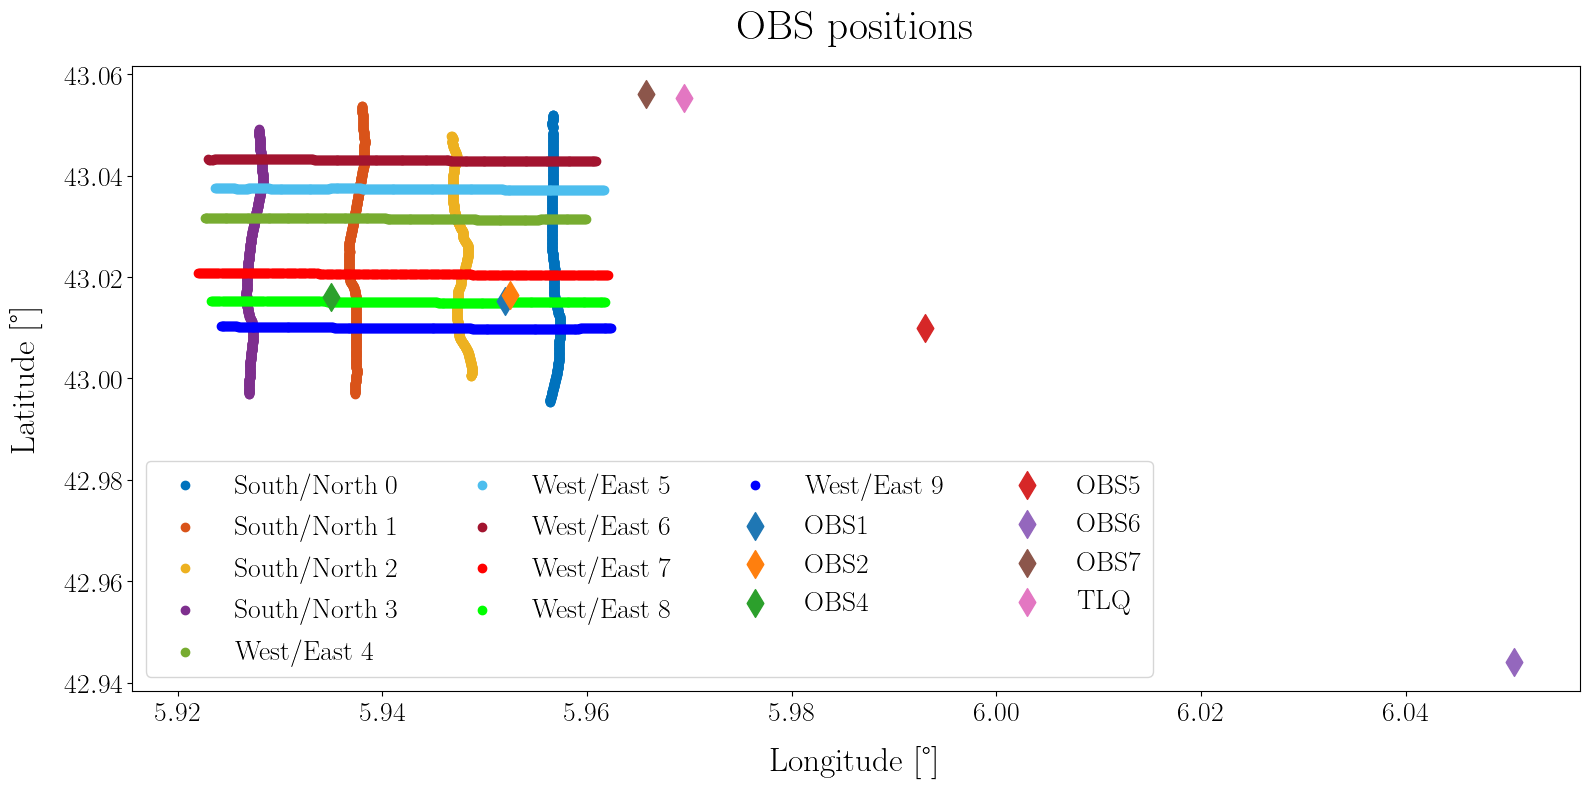

In [6]:
plot_portion_tir_pos(portion_tree=portion)

# Analyse de la structure de variété des données 

## Choix de l'intersection 
On s'intéresse ici à une unique intersection 

In [227]:
obs_ids = ["obs1", "obs2", "obs4", "obs7"]

test_section = "oe7"
sections = ["sn2"]
reference_rcv = 'obs1'
fmin = 10
fmax = 500

library_rtf_method = "spectral_ratio"
event_rtf_method = "spectral_ratio"

In [228]:
portion = portion.sel(freq=slice(fmin, fmax))
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

In [229]:
# The test section plays the role of the event
portion_event = build_portion_event_from_active_section(
    portion,
    test_section,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    rtf_method=event_rtf_method,
)
portion_event

<xarray.DataTree>
Group: /
│   Attributes:
│       description:  Event built from the section 'oe7'
├── Group: /position
│   └── Group: /position/oe7
│           Dimensions:   (datetime: 376)
│           Coordinates:
│             * datetime  (datetime) datetime64[ns] 3kB 2026-02-25T06:04:00.600098 ... 20...
│           Data variables:
│               lon       (datetime) float64 3kB 5.962 5.962 5.962 ... 5.923 5.922 5.922
│               lat       (datetime) float64 3kB 43.02 43.02 43.02 ... 43.02 43.02 43.02
│           Attributes: (12/13)
│               description:            Localisation features
│               campagne:               ACOUPLANE
│               geodesic_frame:         WGS84
│               portion_id:             5
│               section_orientation:    West/East
│               section_id:             7
│               ...                     ...
│               obs_position:           OBS position corrected using LMS inversion.
│               obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
│               reference_receiver:     obs1
│               rtf_method:             spectral_ratio
│               acquisition_mode:       active
│               event_id:               oe7
└── Group: /feature
    └── Group: /feature/oe7
            Dimensions:         (rcv_id_feature: 5, event_datetime: 376, freq: 2008,
                                 rcv_id: 7)
            Coordinates:
              * rcv_id_feature  (rcv_id_feature) <U4 80B 'obs2' 'obs4' 'obs5' 'obs6' 'obs7'
              * event_datetime  (event_datetime) datetime64[ns] 3kB 2026-02-25T06:04:00.6...
              * freq            (freq) float64 16kB 10.01 10.25 10.5 ... 499.5 499.8 500.0
              * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
            Data variables:
                pi_ij           (rcv_id_feature, event_datetime, freq) complex64 30MB (3....
                gamma_ij        (rcv_id_feature, event_datetime, freq) float32 15MB 11.71...
                sij_scot        (rcv_id_feature, event_datetime, freq) complex64 30MB (0....
                event_lon       (event_datetime) float64 3kB 5.962 5.962 ... 5.922 5.922
                event_lat       (event_datetime) float64 3kB 43.02 43.02 ... 43.02 43.02
                rcv_lon         (rcv_id) float64 56B ...
                rcv_lat         (rcv_id) float64 56B ...
                rcv_immersion   (rcv_id) int16 14B ...
            Attributes:
                description:            Localisation features
                campagne:               ACOUPLANE
                geodesic_frame:         WGS84
                portion_id:             5
                section_orientation:    West/East
                section_id:             7
                section_label:          oe7
                obs_position:           OBS position corrected using LMS inversion.
                obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
                reference_receiver:     obs1
                rtf_method:             spectral_ratio
                acquisition_mode:       active

In [230]:
# Sections of the portion kept in the library
portion_library = build_portion_library(
    portion,
    sections=sections,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    acquisition_mode="active",
    verbose=True,
)
portion_library

    Library section 'sn2' (active, RTF 'spectral_ratio')


<xarray.DataTree>
Group: /
│   Attributes:
│       description:         Library of reference features
│       acquisition_mode:    active
│       reference_receiver:  obs1
│       rtf_method:          spectral_ratio
├── Group: /position
│   └── Group: /position/sn2
│           Dimensions:   (datetime: 685)
│           Coordinates:
│             * datetime  (datetime) datetime64[ns] 5kB 2026-02-25T07:28:00.600098 ... 20...
│           Data variables:
│               lon       (datetime) float64 5kB 5.947 5.947 5.947 ... 5.949 5.949 5.949
│               lat       (datetime) float64 5kB 43.05 43.05 43.05 43.05 ... 43.0 43.0 43.0
│           Attributes:
│               description:            Localisation features
│               campagne:               ACOUPLANE
│               geodesic_frame:         WGS84
│               portion_id:             5
│               section_orientation:    South/North
│               section_id:             2
│               section_label:          sn2
│               obs_position:           OBS position corrected using LMS inversion.
│               obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
│               reference_receiver:     obs1
│               rtf_method:             spectral_ratio
│               acquisition_mode:       active
└── Group: /feature
    └── Group: /feature/sn2
            Dimensions:           (rcv_id_feature: 5, library_datetime: 685, freq: 2008,
                                   rcv_id: 7)
            Coordinates:
              * rcv_id_feature    (rcv_id_feature) <U4 80B 'obs2' 'obs4' ... 'obs6' 'obs7'
              * library_datetime  (library_datetime) datetime64[ns] 5kB 2026-02-25T07:28:...
              * freq              (freq) float64 16kB 10.01 10.25 10.5 ... 499.5 499.8 500.0
              * rcv_id            (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
            Data variables:
                pi_ij             (rcv_id_feature, library_datetime, freq) complex64 55MB ...
                gamma_ij          (rcv_id_feature, library_datetime, freq) float32 28MB 1...
                sij_scot          (rcv_id_feature, library_datetime, freq) complex64 55MB ...
                library_lon       (library_datetime) float64 5kB 5.947 5.947 ... 5.949 5.949
                library_lat       (library_datetime) float64 5kB 43.05 43.05 ... 43.0 43.0
                rcv_lon           (rcv_id) float64 56B ...
                rcv_lat           (rcv_id) float64 56B ...
                rcv_immersion     (rcv_id) int16 14B ...
            Attributes:
                description:            Localisation features
                campagne:               ACOUPLANE
                geodesic_frame:         WGS84
                portion_id:             5
                section_orientation:    South/North
                section_id:             2
                section_label:          sn2
                obs_position:           OBS position corrected using LMS inversion.
                obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
                reference_receiver:     obs1
                rtf_method:             spectral_ratio
                acquisition_mode:       active

In [231]:
portion_mfp = apply_mfp_strategy_to_portions(
    portion_library=portion_library,
    portion_event=portion_event,
    rcv_ref=reference_rcv,
    fmin=fmin,
    fmax=fmax,
    verbose=True,
    compare_centered_gamma=True,
    library_sections=None,
    event_sections=None,
    obs_ids=obs_ids,
)
portion_mfp

    Library 'sn2' x event 'oe7' (1/1)


<xarray.DataTree>
Group: /
│   Attributes:
│       description:         MFP between a library and events
│       reference_receiver:  obs1
└── Group: /mfp_intersection
    └── Group: /mfp_intersection/sn2
        └── Group: /mfp_intersection/sn2/oe7
                Dimensions:                 (rcv_id: 7, library_datetime: 685,
                                             event_datetime: 376, rcv_id_feature: 3)
                Coordinates:
                  * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
                  * library_datetime        (library_datetime) datetime64[ns] 5kB 2026-02-25T...
                  * event_datetime          (event_datetime) datetime64[ns] 3kB 2026-02-25T06...
                  * rcv_id_feature          (rcv_id_feature) <U4 48B 'obs2' 'obs4' 'obs7'
                Data variables: (12/14)
                    rcv_lon                 (rcv_id) float64 56B ...
                    rcv_lat                 (rcv_id) float64 56B ...
                    rcv_immersion           (rcv_id) int16 14B ...
                    library_lon             (library_datetime) float64 5kB 5.947 5.947 ... 5.949
                    library_lat             (library_datetime) float64 5kB 43.05 43.05 ... 43.0
                    event_lon               (event_datetime) float64 3kB 5.962 5.962 ... 5.922
                    ...                      ...
                    d_theta                 (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                    d_theta_gamma           (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                    d_L2_gamma              (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                    d_dcf                   (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                    d_theta_gamma_centered  (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                    d_L2_gamma_centered     (rcv_id_feature, library_datetime, event_datetime) float64 6MB ...
                Attributes:
                    description:               MFP result for a library section and an event
                    campagne:                  ACOUPLANE
                    section1:                  sn2
                    section2:                  oe7
                    library_acquisition_mode:  active
                    event_acquisition_mode:    active
                    reference_receiver:        obs1
                    obs_position:              OBS position corrected using LMS inversion.
                    obs_position_filepath:     C:\Users\baptiste.menetrier\Desktop\devPy\phd\...

### Définition de la méthode d'apprentissage de variété

On utilise ici la méthode ISOMAP qui à pour propriété (pour objectif) de préserver les distances géodésiques entre éléments du jeu de données. 

**Remarque** : on utilise ici le mode *metric = precomputed* qui permet de fournir directement une matrice de distance $M$ décrivant la distance entre chaque pair d'éléments du jeu de données.  

### Calcul de la matrice des distances 

In [232]:
receiver = 'obs2'

#### Restriction de la portion aux paramètres d'étude 

In [233]:
portion_ = portion.sel(freq=slice(fmin, fmax))
portion_ = portion_.sel(rcv_id_feature=[receiver])
portion_.feature.sn0

<xarray.DataTree 'sn0'>
Group: /feature/sn0
    Dimensions:                 (rcv_id: 7, src_datetime: 787, rcv_i: 6, rcv_j: 6,
                                 freq: 2008, rcv_id_feature: 1)
    Coordinates:
      * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
      * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
      * rcv_i                   (rcv_i) <U4 96B 'obs1' 'obs2' ... 'obs6' 'obs7'
      * rcv_j                   (rcv_j) <U4 96B 'obs1' 'obs2' ... 'obs6' 'obs7'
      * freq                    (freq) float64 16kB 10.01 10.25 10.5 ... 499.8 500.0
      * rcv_id_feature          (rcv_id_feature) <U4 16B 'obs2'
    Data variables:
        rcv_lon                 (rcv_id) float64 56B ...
        rcv_lat                 (rcv_id) float64 56B ...
        rcv_immersion           (rcv_id) int16 14B ...
        tir_src_lon             (src_datetime) float64 6kB ...
        tir_src_lat             (src_datetime) float64 6kB ...
        src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
        tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
        tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
        Sxy                     (src_datetime, rcv_i, rcv_j, freq) complex64 455MB ...
        pi_ij                   (rcv_id_feature, src_datetime, freq) complex64 13MB ...
        gamma_ij                (rcv_id_feature, src_datetime, freq) float32 6MB ...
        sij_scot                (rcv_id_feature, src_datetime, freq) complex64 13MB ...
    Attributes:
        description:            Localisation features
        campagne:               ACOUPLANE
        geodesic_frame:         WGS84
        portion_id:             5
        section_orientation:    South/North
        section_id:             0
        section_label:          sn0
        obs_position:           OBS position corrected using LMS inversion.
        obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
        reference_receiver:     obs1

In [234]:
# name = list(portion_library.feature.children)[0]
# ds_feature_a = portion.feature[name].sel(rcv_id_feature=[receiver]).to_dataset()
# name = list(portion_event.feature.children)[0]
# ds_feature_b = portion.feature[name].sel(rcv_id_feature=[receiver]).to_dataset()
# ds_feature_combined = xr.concat(
#     [ds_feature_a, ds_feature_b], dim="src_datetime", data_vars="all"
# )
# ds_feature_combined
# ds_feature_a, ds_feature_b

portion_ = portion_.sel(rcv_id_feature=[receiver])
selected_sections = [test_section, sections[0]]
# Use all if none
if selected_sections is None:
    selected_sections = list(portion_.position.children)

var_to_keep = [
    "pi_ij",
    "gamma_ij",
    "sij_scot",
    "freq",
    "rcv_id_feature",
    "tir_src_lon",
    "tir_src_lat",
    "src_datetime",
]
var_to_drop = [
    var
    for var in list(portion_.feature[selected_sections[0]].to_dataset().variables)
    if var not in var_to_keep
]
sections_to_combined = []
for section in selected_sections:
    ds_section = portion_.feature[section].to_dataset()
    ds_section = ds_section.drop_vars(var_to_drop)
    sections_to_combined.append(ds_section)

ds_feature_combined = xr.concat(sections_to_combined, dim="src_datetime")
ds_feature_combined

<xarray.Dataset> Size: 43MB
Dimensions:         (src_datetime: 1061, rcv_id_feature: 1, freq: 2008)
Coordinates:
  * src_datetime    (src_datetime) datetime64[ns] 8kB 2026-02-25T06:04:00.600...
  * rcv_id_feature  (rcv_id_feature) <U4 16B 'obs2'
  * freq            (freq) float64 16kB 10.01 10.25 10.5 ... 499.5 499.8 500.0
Data variables:
    tir_src_lon     (src_datetime) float64 8kB 5.962 5.962 5.962 ... 5.949 5.949
    tir_src_lat     (src_datetime) float64 8kB 43.02 43.02 43.02 ... 43.0 43.0
    pi_ij           (rcv_id_feature, src_datetime, freq) complex64 17MB (3.84...
    gamma_ij        (rcv_id_feature, src_datetime, freq) float32 9MB 11.71 .....
    sij_scot        (rcv_id_feature, src_datetime, freq) complex64 17MB (0.99...
Attributes:
    description:            Localisation features
    campagne:               ACOUPLANE
    geodesic_frame:         WGS84
    portion_id:             5
    section_orientation:    West/East
    section_id:             7
    section_label:          oe7
    obs_position:           OBS position corrected using LMS inversion.
    obs_position_filepath:  C:\Users\baptiste.menetrier\Desktop\devPy\phd\rea...
    reference_receiver:     obs1

In [235]:
feature_distances = feature_distances_between_datasets(
    ds_feature_a=ds_feature_combined,
    ds_feature_b=ds_feature_combined,
    compare_centered_gamma=True,
)

In [236]:
# Pick among available :['dist_theta',
#  'dist_theta_gamma',
#  'dist_L2_gamma',
#  'dist_dcf',
#  'dist_theta_gamma_centered',
#  'dist_L2_gamma_centered']
dist_metric = "dist_theta_gamma_centered"

dist_matrix = feature_distances[dist_metric]
# Remove rcv dimension = 1
dist_matrix = np.squeeze(dist_matrix)   
dist_matrix.shape

(1061, 1061)

### Importance relative des coordonnées en projection 

Pour ce faire, on peut commencer par projeter dans un espace de dimension importante (ici D = 200) et étudier l'importance relative de chacune des coordonnées. Pour ce faire, on utilise une approche similaire à l'approche de l'ACP et on représente la variance (ou bien de manière équivalente le pourcentage de variance cumulée) associé à chaque dimension. 

L'objectif est de vérifier que la variance décroit rapidement signifiant que les premières dimensions encode la majeure partie de l'information et que l'on peut donc réduire la dimension des données en préservant l'information importante à la localisation. 

In [237]:
from sklearn import manifold
from sklearn.preprocessing import StandardScaler

In [238]:
n_neighbors_ = np.arange(5, 100, 5).astype(int)
n_components = 200
reconstruction_error = []
coords_var = []
for n_neighbors in n_neighbors_:
    # Define isomap object
    iso = manifold.Isomap(
        n_neighbors=n_neighbors,
        n_components=n_components,
        metric="precomputed",
    )
    # Learn manifold and project data in target dimension
    coords = iso.fit_transform(dist_matrix)
    cvar = np.var(coords, axis=0)
    cvar = cvar / cvar.max()

    coords_var.append(cvar)
    reconstruction_error.append(iso.reconstruction_error())

coords_var = np.asarray(coords_var)
reconstruction_error = np.asarray(reconstruction_error)

Text(0, 0.5, 'Variance')

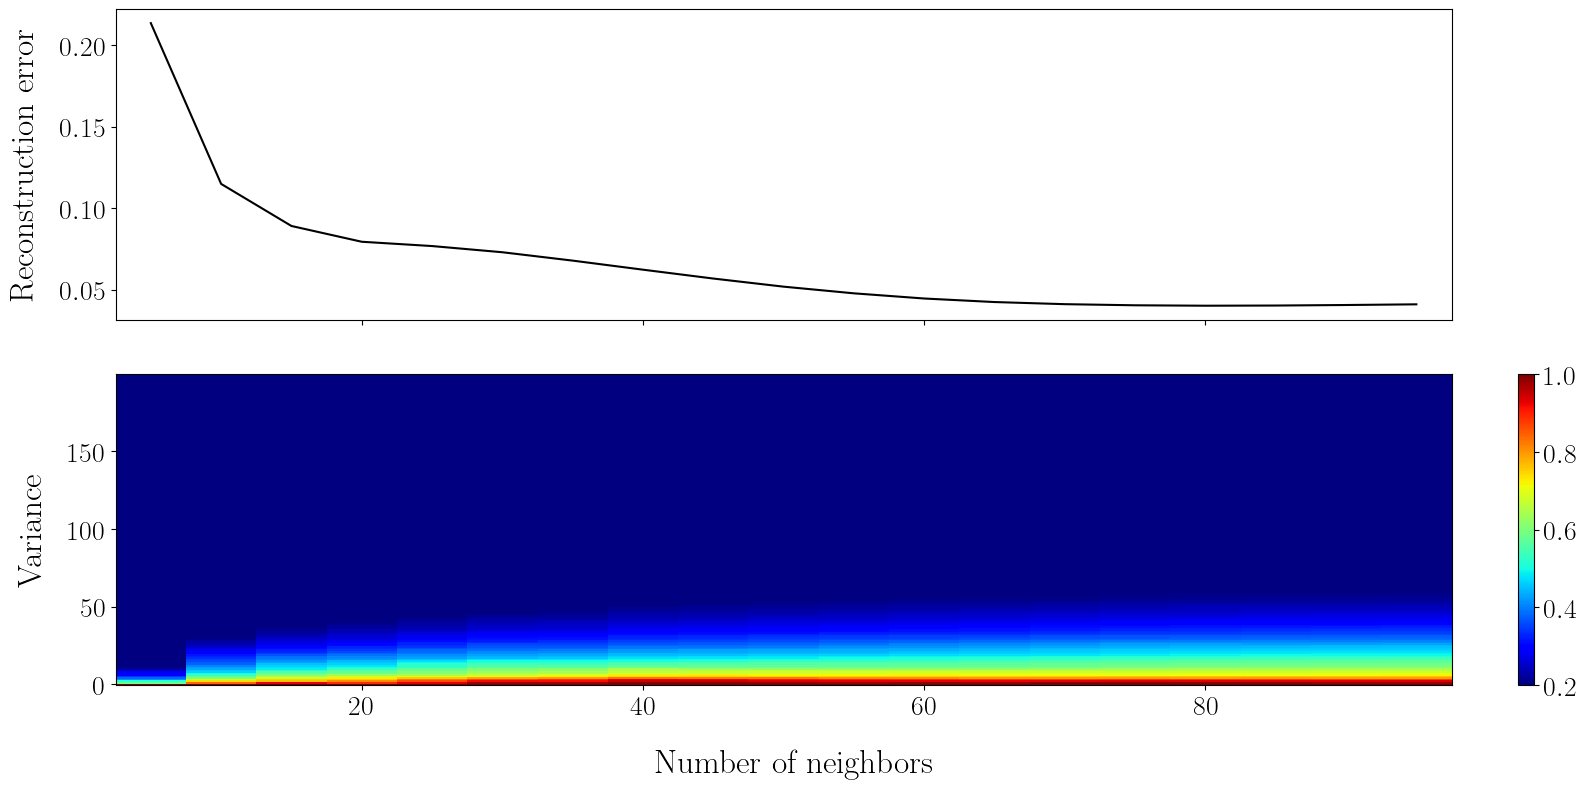

In [239]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
axs[0].plot(n_neighbors_, reconstruction_error, color="k")
im = axs[1].pcolormesh(n_neighbors_, np.arange(n_components), coords_var.T, cmap="jet", vmin=0.2)
plt.colorbar(im, ax=axs[1])

fig.supxlabel("Number of neighbors")
axs[0].set_ylabel("Reconstruction error")
axs[1].set_ylabel("Variance")

**Choix des paramètres ISOMAP** Le choix du nombre de voisins est un compromis ici entre l'erreur de reconstruction et la vitesse de décroissance de la variance des coordonnées. Le nombre de voisins à cependant une faible influence sur la variance des coordonnées. 

Le choix n = 20 semble être un bon compromis avec une relativement faible erreur de reconstruction et un gradient relativement important de la variance. 


In [240]:
# ISOMAP
n_components = 200
n_neighbors = 20

# Define isomap object
isomap_obj = manifold.Isomap(
    n_neighbors=n_neighbors,
    n_components=n_components,
    metric="precomputed",
)

In [241]:
# Learn manifold and project data in target dimension
coords = isomap_obj.fit_transform(dist_matrix)

# Normalize coords
norm_factor = np.max(coords)
coords /= norm_factor

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_5204\606414193.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


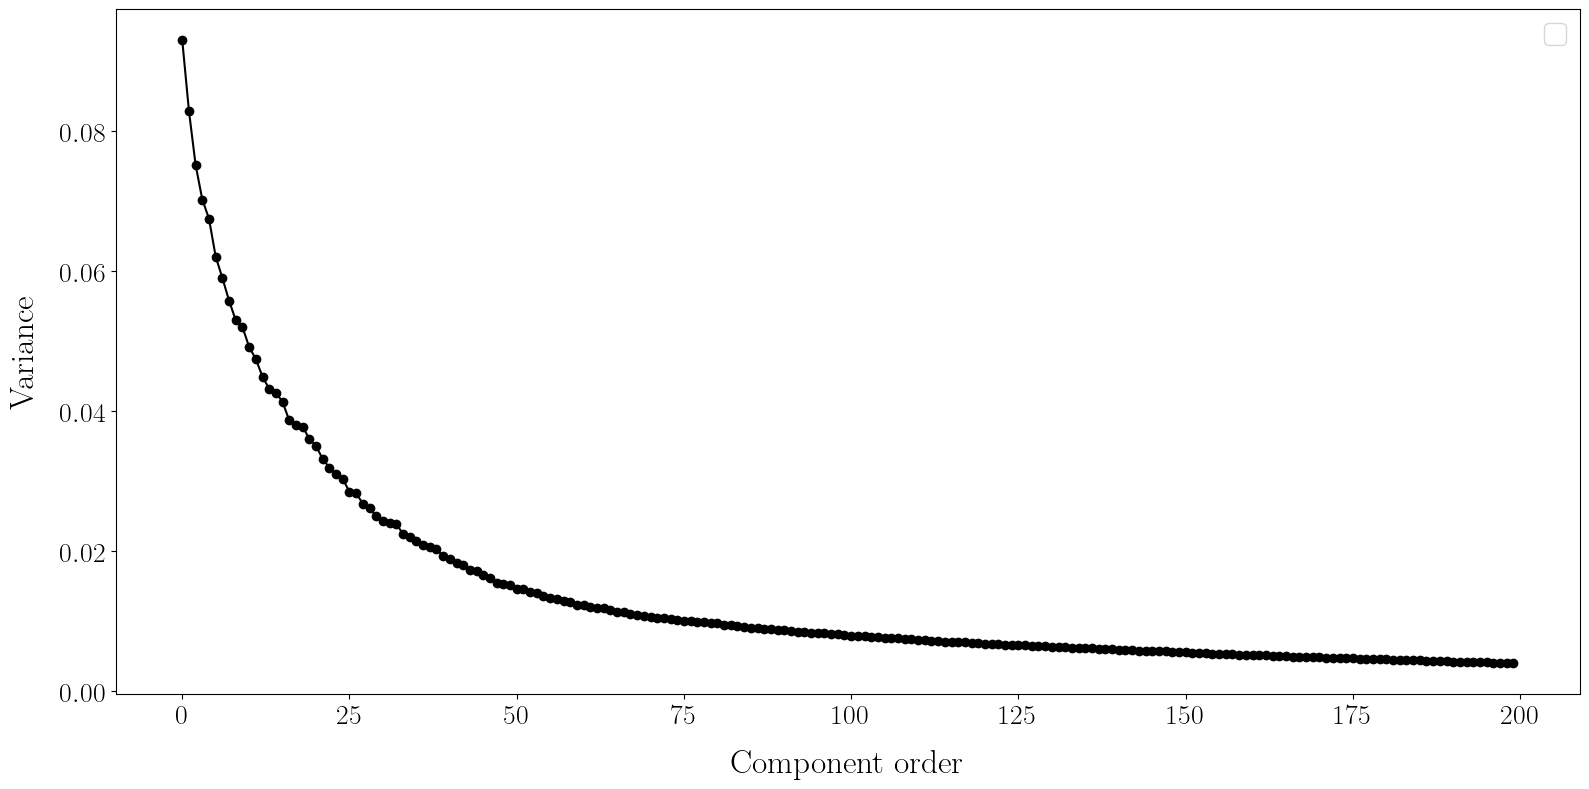

In [242]:
# Plot variance of each component
cvar = np.var(coords, axis=0)
plt.figure()
plt.plot(np.arange(cvar.size), cvar, marker="o", color="k")
plt.xlabel("Component order")
plt.ylabel("Variance")
plt.legend()
# plt.ylim(0, 0.05)

On peut vérifier que l'erreur de reconstruction décroit rapidement. 

In [244]:
proj_dims = np.arange(10, n_components, 10).astype(int)

reconstruction_error = []
for p_dim in proj_dims:
    # Define isomap object
    iso = manifold.Isomap(
        n_neighbors=n_neighbors,
        n_components=p_dim,
        metric="precomputed",
    )
    # Learn manifold and project data in target dimension
    iso.fit(dist_matrix)

    reconstruction_error.append(iso.reconstruction_error())

reconstruction_error = np.asarray(reconstruction_error)

Text(0, 0.5, 'Reconstruction error')

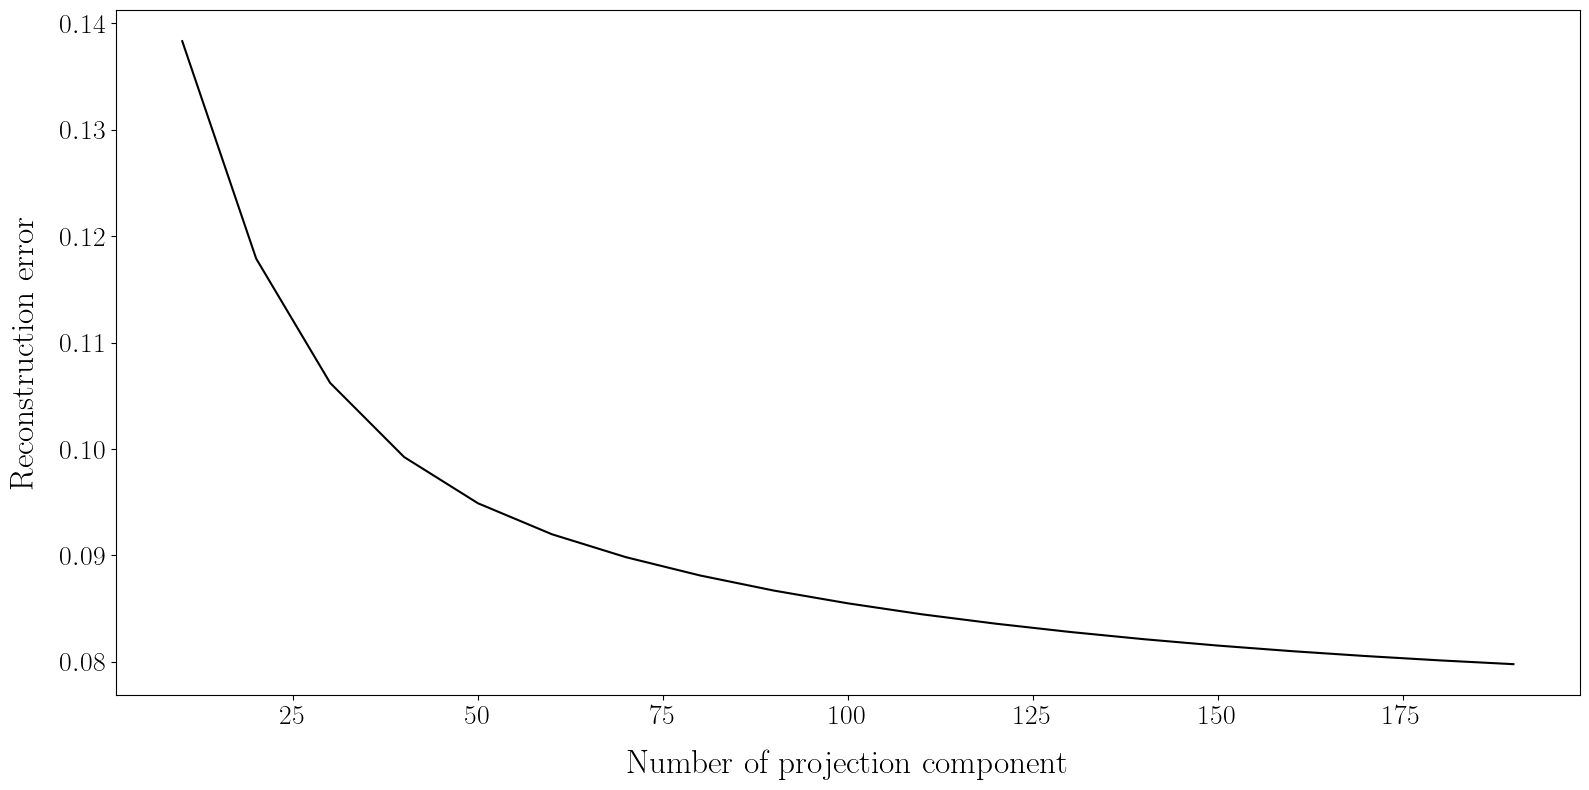

In [245]:
plt.figure()
plt.plot(proj_dims, reconstruction_error, color="k")
plt.xlabel("Number of projection component")
plt.ylabel("Reconstruction error")

On réduit ensuite la dimension à d = 50. 

In [255]:
low_dim = 50
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

dist_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim[:, np.newaxis, :] - coords_low_dim[np.newaxis, :, :]) ** 2,
        axis=-1,
    )
)

In [256]:
# Assign low_dim coordinates to corresponding section to analyse intersections
sections_to_combined = []
for section in selected_sections:
    ds_section = portion_.feature[section].to_dataset()
    ds_section = ds_section.drop_vars(var_to_drop)
    sections_to_combined.append(ds_section)

ds_feature_combined = xr.concat(sections_to_combined, dim="src_datetime")
ds_feature_combined
# coords_low_dim -> shape = (src_datetime_combined, low_dim)
idx_start_section = 0
idx_stop_section = 0
for ds_section in sections_to_combined:
    # Update stop
    idx_stop_section += ds_section.sizes["src_datetime"]
    # Extract section low dim coordinates
    coords_low_dim_section = coords_low_dim[idx_start_section:idx_stop_section, :]
    # Update start
    idx_start_section = idx_stop_section

    # Store
    ds_section.coords["isomap_dimension"] = np.arange(low_dim)
    ds_section["isomap_coords"] = (["src_datetime", "isomap_dimension"], coords_low_dim_section)

isec1 = 0
ds_section1 = sections_to_combined[isec1]
section1_name = selected_sections[isec1]

isec2 = 1
ds_section2 = sections_to_combined[isec2]
section2_name = selected_sections[isec2]

In [257]:
dist_12 = get_distance_between_sections(ds_section1, ds_section2)
dist_12 = dist_12.T  # NOTE : transpose for backward compatibility

xmin, ymin = find_min_distance_position(
    dt1=ds_section1.src_datetime,
    dt2=ds_section2.src_datetime,
    dist=dist_12,
)

Reduction to 1 dimensions, percentage of reduction = 99.95%
Reduction to 6 dimensions, percentage of reduction = 99.70%
Reduction to 11 dimensions, percentage of reduction = 99.45%
Reduction to 16 dimensions, percentage of reduction = 99.20%
Reduction to 21 dimensions, percentage of reduction = 98.95%
Reduction to 26 dimensions, percentage of reduction = 98.71%
Reduction to 31 dimensions, percentage of reduction = 98.46%
Reduction to 36 dimensions, percentage of reduction = 98.21%


Text(0.02, 0.5, 'Time along South/North 2 trajectory')

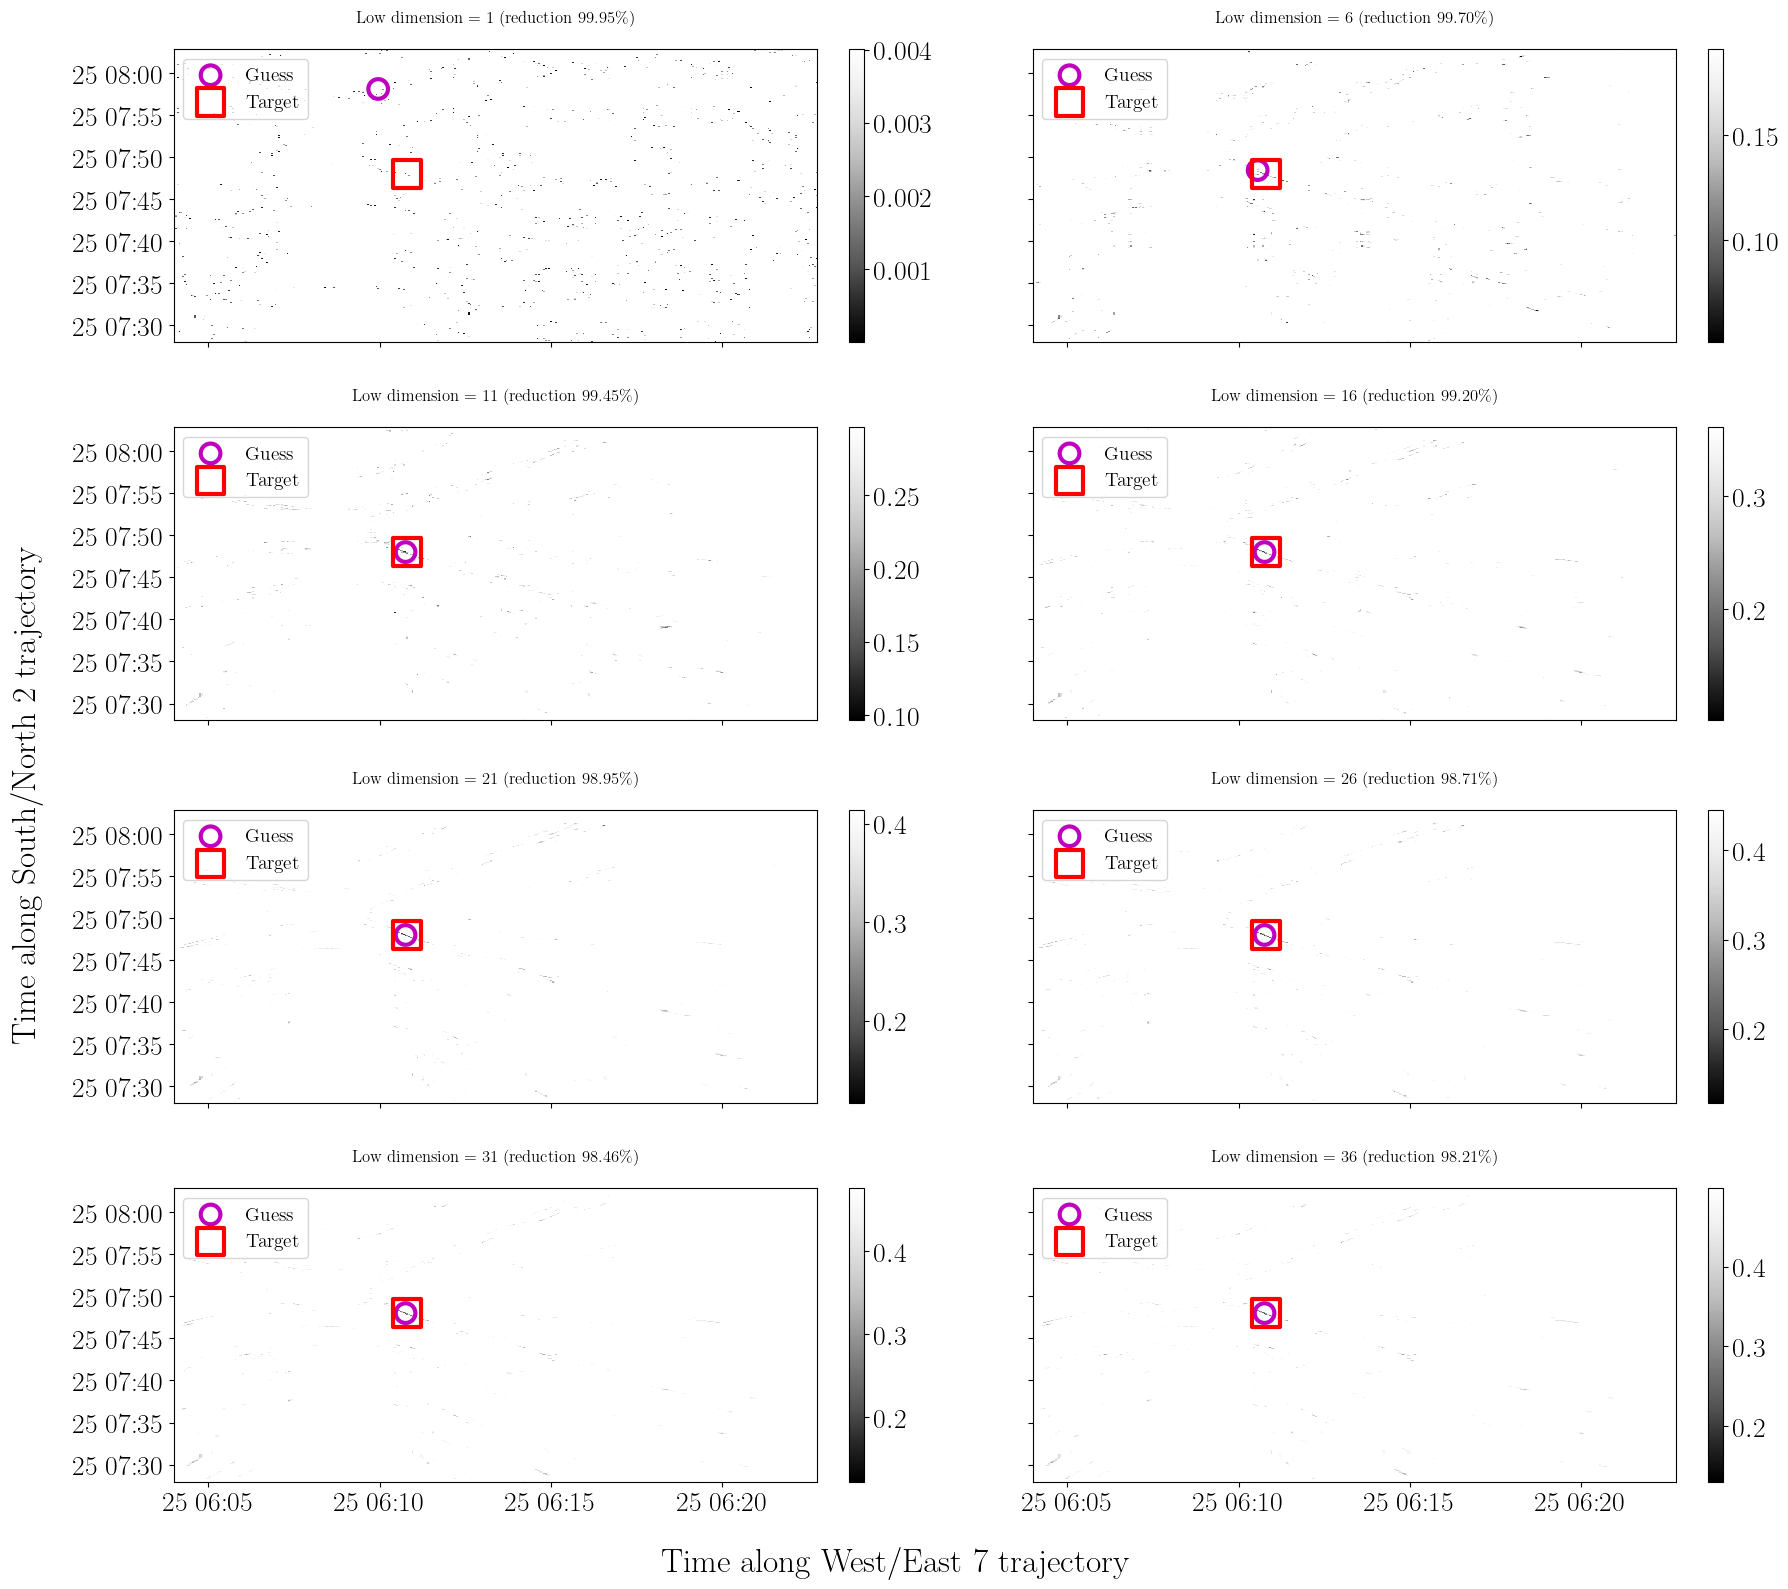

In [260]:
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(18, 16), sharex=True, sharey=True)
axs = axs.flatten()
i = 0
for low_dim in range(1, 41, 5):

    dim_red = 100 * (1 - low_dim / ds_section1.sizes["freq"])
    print(
        f"Reduction to {low_dim} dimensions, percentage of reduction = {dim_red:.2f}%"
    )
    coords_low_dim = coords[:, :low_dim]
    coords_low_dim.shape

    # Split back into section 1 and section 2
    coords_low_dim_a = coords_low_dim[: ds_section1.sizes["src_datetime"], :]
    coords_low_dim_b = coords_low_dim[ds_section1.sizes["src_datetime"] :, :]

    # Compute L2 distance in low dimension
    dist_low_dim = np.sqrt(
        np.nansum(
            (coords_low_dim_a[:, np.newaxis, :] - coords_low_dim_b[np.newaxis, :, :])
            ** 2,
            axis=-1,
        )
    )
    dist_low_dim = dist_low_dim / dist_low_dim.max()

    # ind_min_low_dim = np.argmin(dist_low_dim.T)
    # xmin_low_dim, ymin_low_dim = (
    #     xx.flatten()[ind_min_low_dim],
    #     yy.flatten()[ind_min_low_dim],
    # )
    xmin_low_dim, ymin_low_dim = find_min_distance_position(
        dt1=ds_section1.src_datetime,
        dt2=ds_section2.src_datetime,
        dist=dist_low_dim.T,
    )

    # Plot
    im = axs[i].pcolormesh(
        ds_section1.src_datetime,
        ds_section2.src_datetime,
        dist_low_dim.T,
        cmap="Grays_r",
        vmin=np.nanmin(dist_low_dim),
        vmax=np.nanpercentile(dist_low_dim, 0.9),
        # vmin=vmin,
        # vmax=vmax,
    )
    plt.colorbar(im, ax=axs[i])

    axs[i].scatter(
        xmin_low_dim,
        ymin_low_dim,
        marker="o",
        s=200,
        facecolors="none",
        edgecolors="m",
        label="Guess",
        linewidth=3,
    )
    axs[i].scatter(
        xmin,
        ymin,
        marker="s",
        s=400,
        facecolors="none",
        edgecolors="r",
        label="Target",
        linewidth=3,
    )

    axs[i].set_title(
        f"Low dimension = {low_dim} (reduction {dim_red:.2f}\%)", fontsize=12
    )

    i += 1

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_section1.section_orientation} {ds_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_section2.section_orientation} {ds_section2.section_id} trajectory"
)

In [263]:
low_dim = 15
coords_low_dim = coords[:, :low_dim]
coords_low_dim.shape

dist_low_dim = np.sqrt(
    np.nansum(
        (coords_low_dim[:, np.newaxis, :] - coords_low_dim[np.newaxis, :, :]) ** 2,
        axis=-1,
    )
)

In [264]:
# Assign low_dim coordinates to corresponding section to analyse intersections
sections_to_combined = []
for section in selected_sections:
    ds_section = portion_.feature[section].to_dataset()
    ds_section = ds_section.drop_vars(var_to_drop)
    sections_to_combined.append(ds_section)

ds_feature_combined = xr.concat(sections_to_combined, dim="src_datetime")
ds_feature_combined
# coords_low_dim -> shape = (src_datetime_combined, low_dim)
idx_start_section = 0
idx_stop_section = 0
for ds_section in sections_to_combined:
    # Update stop
    idx_stop_section += ds_section.sizes["src_datetime"]
    # Extract section low dim coordinates
    coords_low_dim_section = coords_low_dim[idx_start_section:idx_stop_section, :]
    # Update start
    idx_start_section = idx_stop_section

    # Store
    ds_section.coords["isomap_dimension"] = np.arange(low_dim)
    ds_section["isomap_coords"] = (["src_datetime", "isomap_dimension"], coords_low_dim_section)

isec1 = 0
ds_section1 = sections_to_combined[isec1]
section1_name = selected_sections[isec1]

isec2 = 1
ds_section2 = sections_to_combined[isec2]
section2_name = selected_sections[isec2]

Text(0.02, 0.5, 'Replica index')

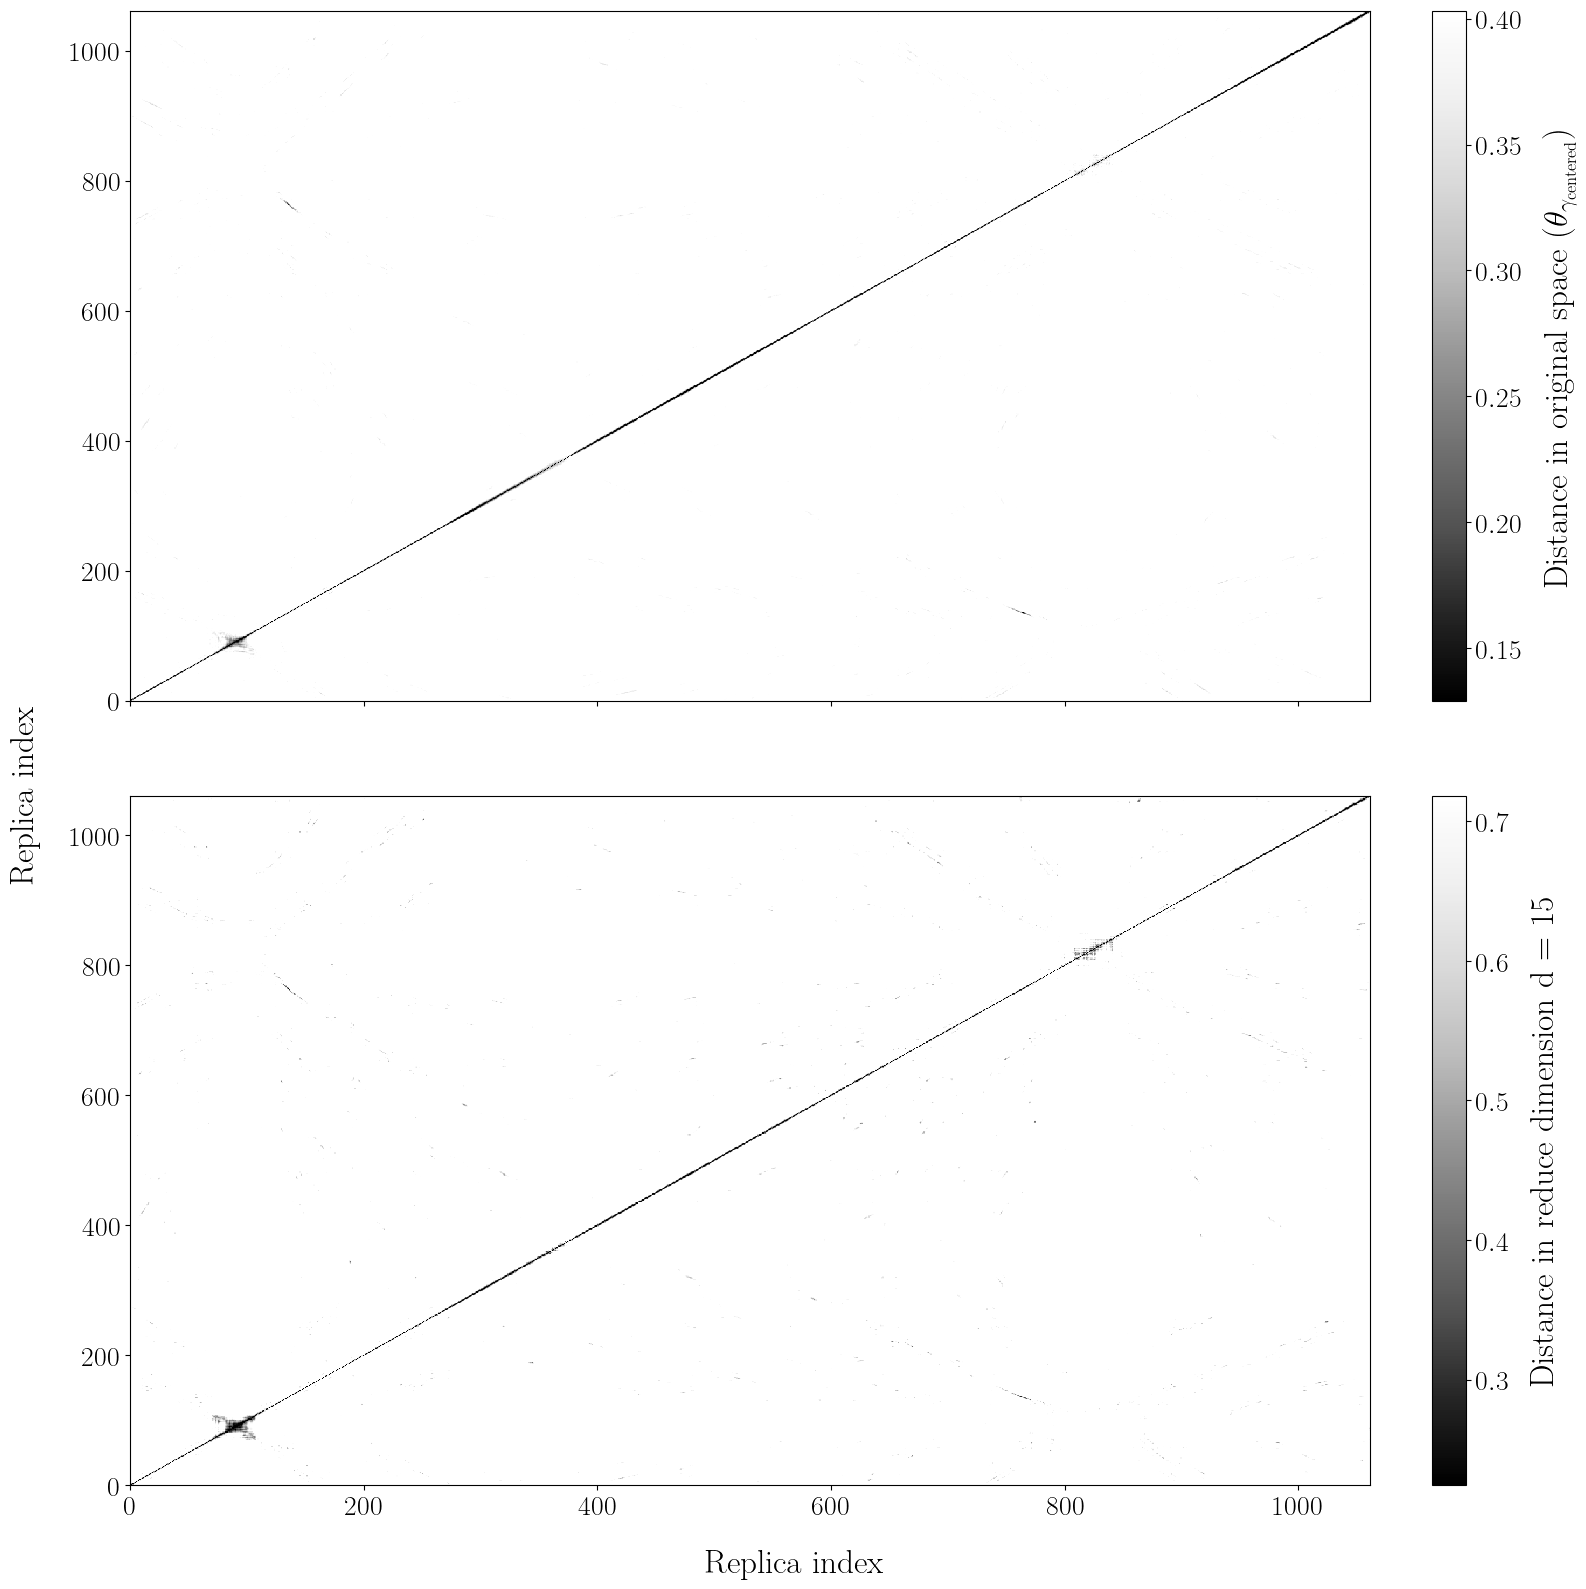

In [267]:
cmap = "Grays_r"
# cmap = "jet_r"
fig, axs = plt.subplots(2, 1, figsize=(16, 16), sharey=True, sharex=True)

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

# im = axs[0].pcolormesh(
#     dist_matrix, cmap="Grays_r", vmin=vmin, vmax=vmax
# )
# im = axs[1].pcolormesh(dist_low_dim, cmap="Grays_r", vmin=vmin, vmax=vmax)


# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# vmin = min(np.percentile(data, 0.05) for data in [dist_matrix, dist_low_dim])
# vmax = max(np.percentile(data, 0.95) for data in [dist_matrix, dist_low_dim])

im = axs[0].pcolormesh(
    dist_matrix,
    cmap=cmap,
    vmin=np.percentile(dist_matrix, 0.1),
    vmax=np.percentile(dist_matrix, 0.95),
)
# plt.colorbar(im, label=r"Distance in original space ($L_{2_\gamma}$)", ax=axs[0])
plt.colorbar(im, label=r"Distance in original space ($\theta_{\gamma_{\text{centered}}}$)", ax=axs[0])

im = axs[1].pcolormesh(
    dist_low_dim,
    cmap=cmap,
    vmin=np.percentile(dist_low_dim, 0.1),
    vmax=np.percentile(dist_low_dim, 0.95),
)
plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}", ax=axs[1])

# fig.colorbar(
#     im,
#     ax=axs[:].tolist(),
#     location="right",
#     label=r"$L_{2_\gamma}$",
#     pad=0.02,
#     fraction=0.04,
# )

# plt.colorbar(im, label=f"Distance in reduce dimension d = {low_dim}")

fig.supxlabel("Replica index")
fig.supylabel("Replica index")

oe7 sn2


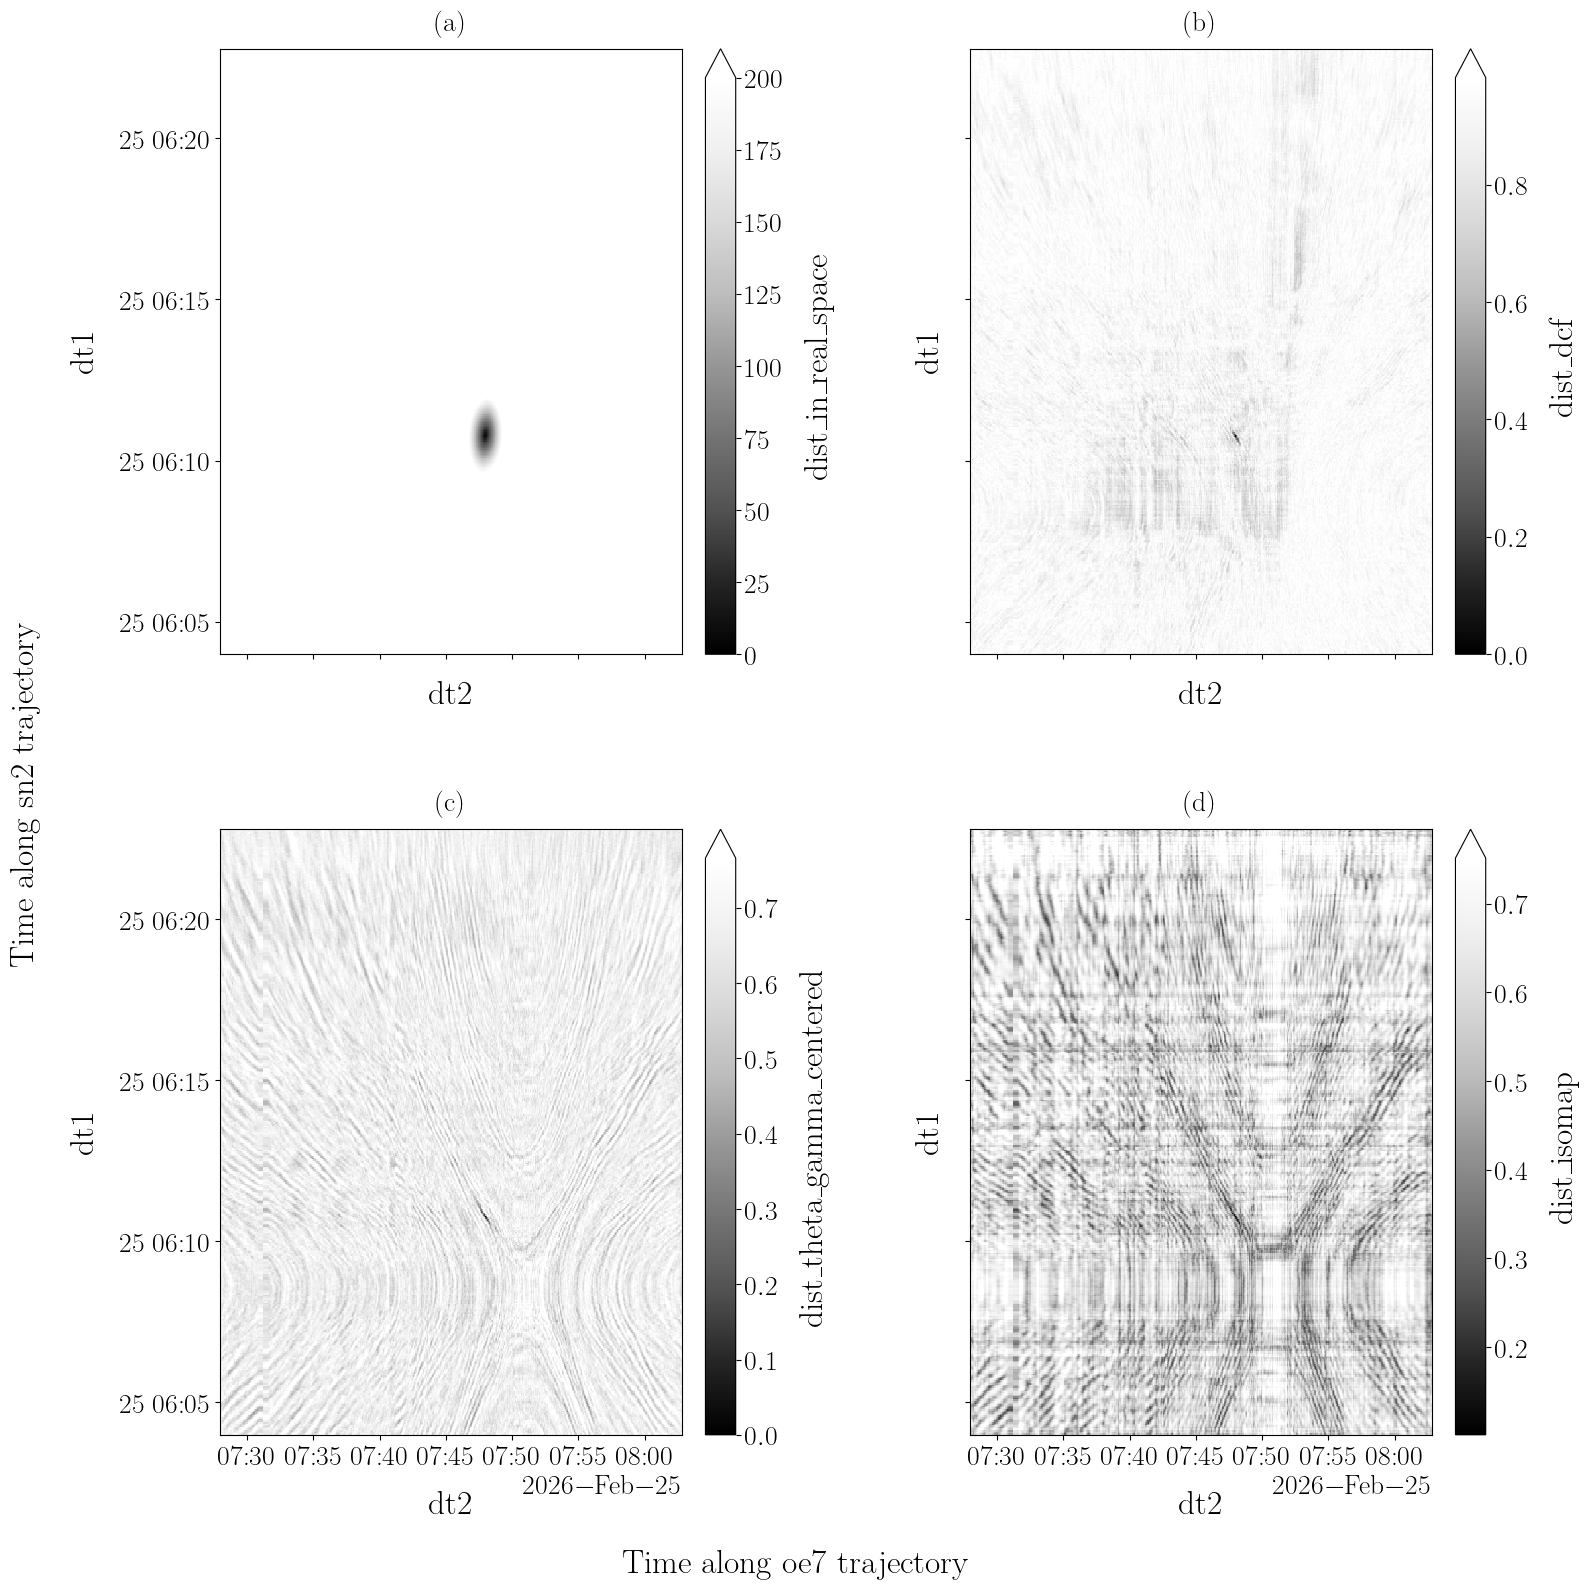

In [268]:
# for isec1, ds_section1 in enumerate(sections_to_combined):
# for isec1 in range(len(sections_to_combined)):


print(section1_name, section2_name)
# Original distance
distance_section12 = distances_single_intersection(
    ds_feature_section1=ds_section1,
    ds_feature_section2=ds_section2,
    compare_centered_gamma=True,
)

# Distance in low dimension using L2
d_L2_low_dim = np.sqrt(
    np.nansum(
        (
            ds_section1.isomap_coords.values[:, np.newaxis, :]
            - ds_section2.isomap_coords.values[np.newaxis, :, :]
        )
        ** 2,
        axis=-1,
    )
)
# Normalize
d_L2_low_dim /= np.nanmax(d_L2_low_dim)

data_vars = {
    d: (["dt1", "dt2"], np.squeeze(distance_section12[d]))
    for d in distance_section12.keys()
}
for k in data_vars.keys():
    if k != "dist_in_real_space":
        # data_vars[k] = (data_vars[k][0], data_vars[k][1]/ np.nanmax(data_vars[k][1]))
        data_vars[k] = (
            data_vars[k][0],
            (data_vars[k][1] - np.nanmin(data_vars[k][1]))
            / (np.nanmax(data_vars[k][1]) - np.nanmin(data_vars[k][1])),
        )

data_vars.update(dict(dist_isomap=(["dt1", "dt2"], d_L2_low_dim)))
ds_mfp = xr.Dataset(
    data_vars=data_vars,
    coords=dict(
        dt1=ds_section1.src_datetime.values, dt2=ds_section2.src_datetime.values
    ),
)

# Plot
cmap = "Grays_r"
max_quantile = 0.95
fig, axs = plt.subplots(
    nrows=2, ncols=2, figsize=(16, 16), sharex=True, sharey=True
)

ds_mfp.dist_in_real_space.plot(ax=axs[0, 0], cmap=cmap, vmin=0, vmax=200)
da = ds_mfp.dist_dcf
da.plot(
    ax=axs[0, 1],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)
da = ds_mfp[dist_metric]
da.plot(
    ax=axs[1, 0],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)
da = ds_mfp.dist_isomap
da.plot(
    ax=axs[1, 1],
    cmap=cmap,
    # vmin=0,
    # vmax=1,
    vmin=da.min(),
    vmax=da.quantile(q=max_quantile),
)

set_subfigures_abc_labels(
    axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom"
)

fig.supxlabel(f"Time along {section1_name} trajectory")
fig.supylabel(f"Time along {section2_name} trajectory")

plt.show()

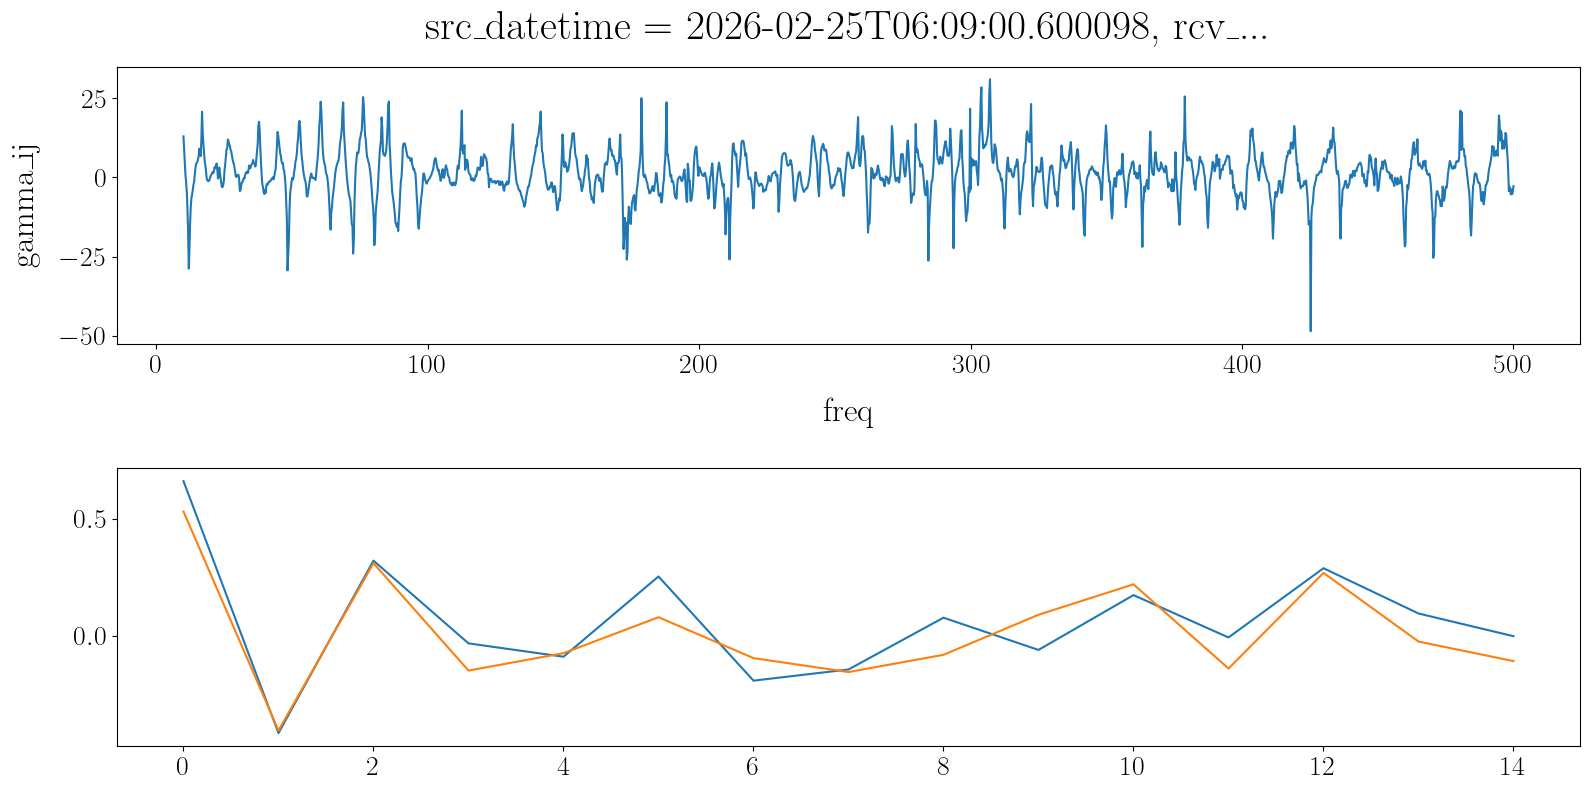

In [269]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ds_feature_combined.gamma_ij.isel(src_datetime=100).plot(x="freq",ax=axs[0])
axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[100, :])
axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[102, :])

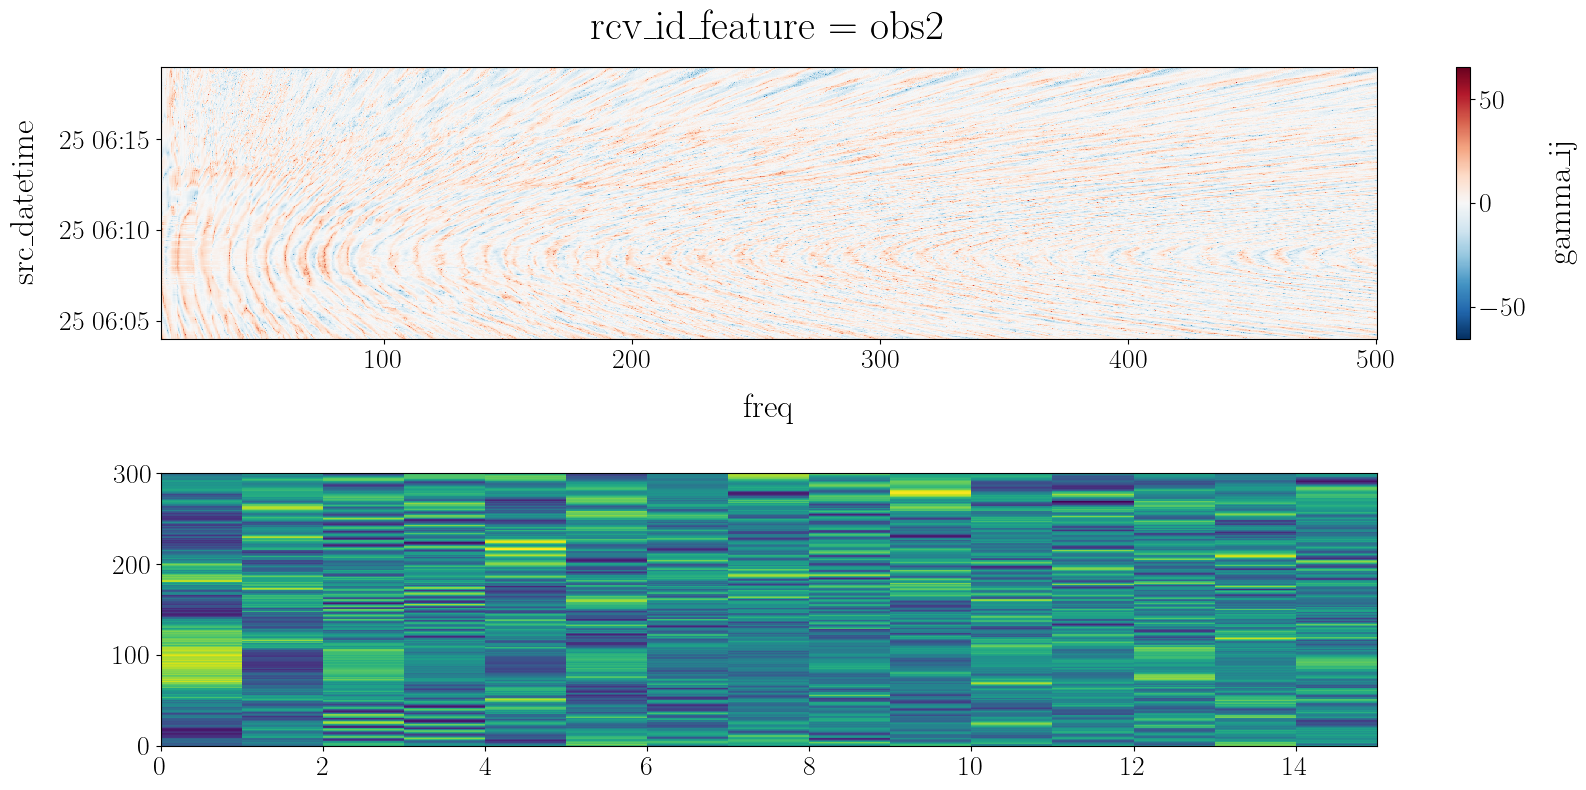

In [270]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))
sl = slice(0, 300)

ds_feature_combined.gamma_ij.isel(src_datetime=sl).plot(x="freq", y="src_datetime", ax=axs[0])
axs[1].pcolormesh(coords_low_dim[sl, :])
# axs[1].plot(np.arange(coords_low_dim[100, :].size), coords_low_dim[102, :])

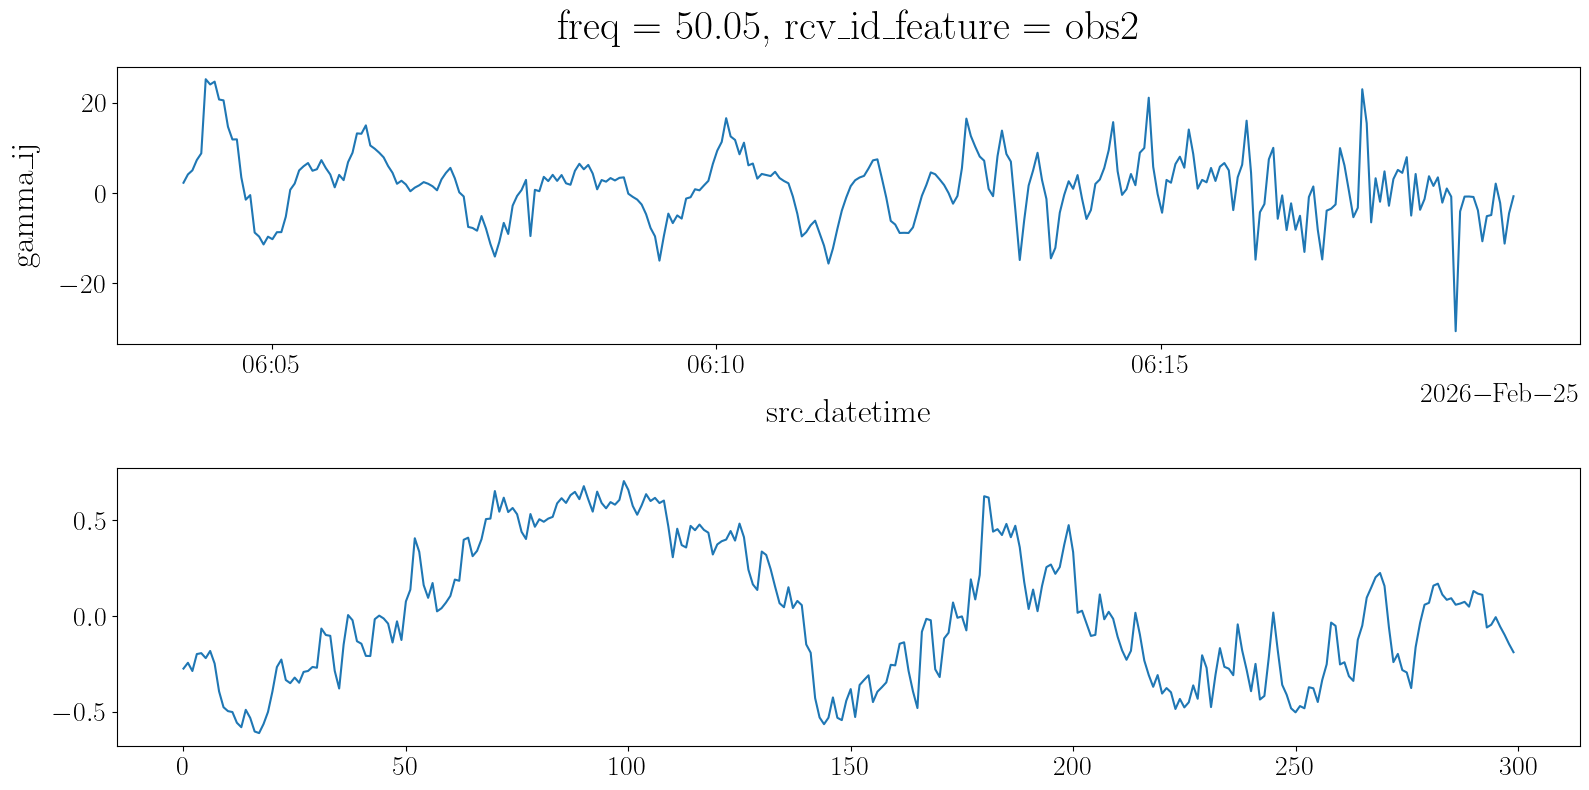

In [271]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

sl = slice(0, 300)
ds_feature_combined.gamma_ij.isel(src_datetime=sl).sel(freq=50, method="nearest").plot(
   ax=axs[0]
)
axs[1].plot(np.arange(coords_low_dim[sl, :].shape[0]), coords_low_dim[sl, 0])
# axs[1].pcolormesh(coords_low_dim[:150, :])

In [275]:
x = ds_feature_combined.gamma_ij.isel(src_datetime=100).isel(rcv_id_feature=0)
df = x.freq.values[1] - x.freq.values[0]
x_fft = np.fft.rfft(x.values)
f_fft = np.fft.rfftfreq(x.size, d=df)

Text(0.5, 0, '$\\tau $ [s]')

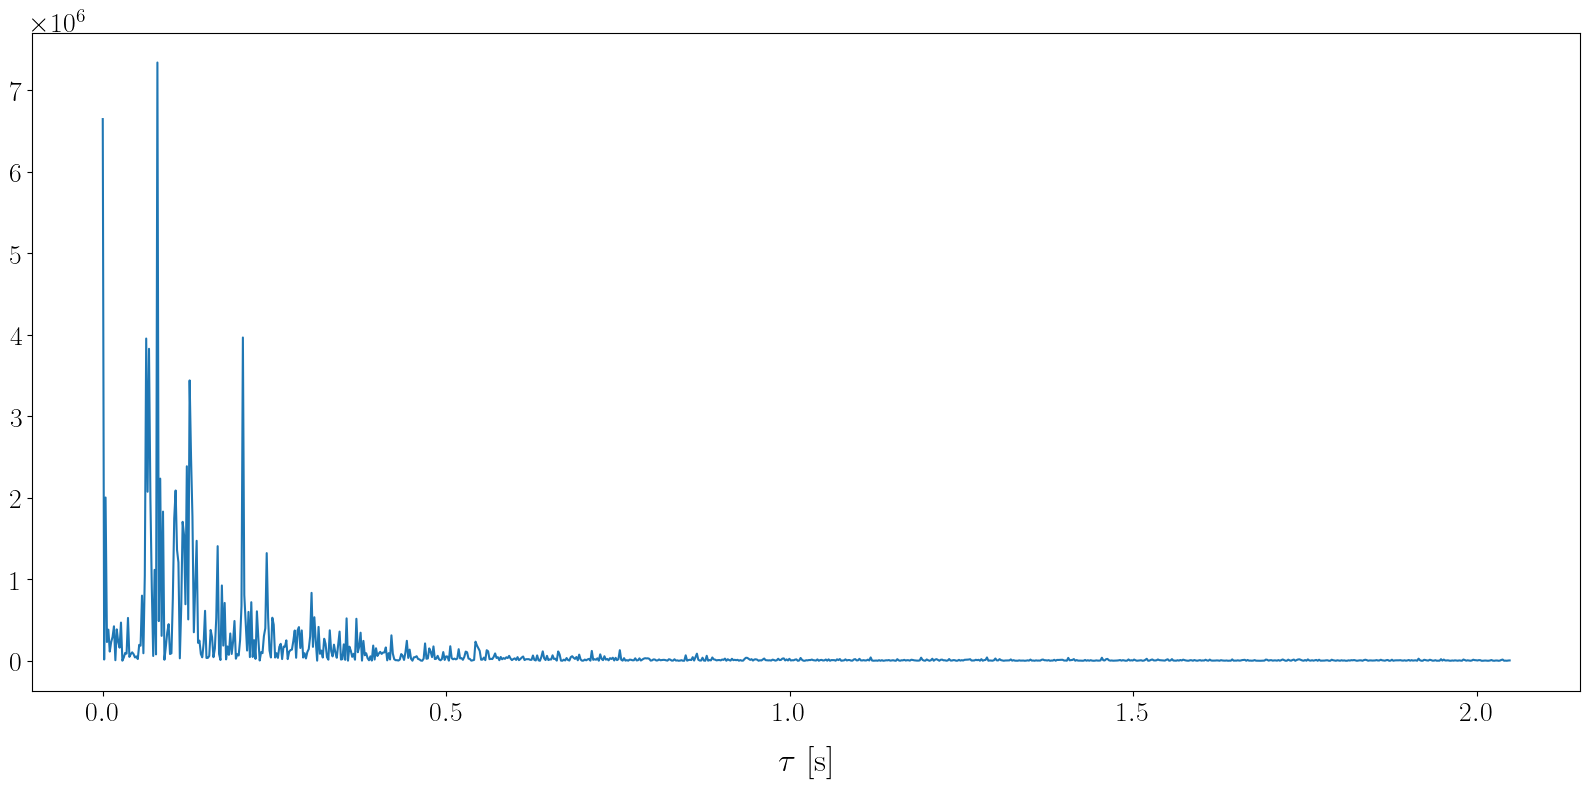

In [278]:
plt.plot(f_fft, np.abs(x_fft)**2)
plt.xlabel(r"$\tau $ [s]")